# Embeddings multimodal · Cohere `embed-v4.0`

Cohere `embed-v4.0` (lanzado 2024-2025) acepta tanto texto como imagen como input y los proyecta al mismo espacio. Esto desbloquea casos de uso muy potentes:

- Buscar fotos por descripción textual ("perro corriendo en la playa")
- Recomendar productos similares a partir de una foto
- RAG sobre PDFs con figuras + texto · sin tener que separar modalidades

Otros modelos multimodales relevantes en 2026: **Voyage Multimodal 3**, **Jina-CLIP v2**, **SigLIP 2** (open). El patrón es el mismo.

## Dependencias

In [1]:
%pip install -q "cohere>=5.13" "pillow" "requests" numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 352.0/352.0 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 56.6 MB/s eta 0:00:00


## Setup

In [2]:
import os, getpass, base64
from pathlib import Path
import numpy as np
import requests

if not os.environ.get("COHERE_API_KEY"):
    os.environ["COHERE_API_KEY"] = getpass.getpass("Cohere API Key: ")

import cohere
co = cohere.Client(os.environ["COHERE_API_KEY"])  # cliente v1 · soporta embed-v4.0 con imágenes

def cos_sim(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

Cohere API Key: ··········


## 1. Preparar 4 imágenes

Para esta demo descargamos 4 imágenes muy distintas semánticamente. Si los URLs caen, puedes sustituir por imágenes locales en `./images/{name}.jpg`.

In [3]:
IMG_DIR = Path("./images_multimodal_demo")
IMG_DIR.mkdir(exist_ok=True)

# URLs de Wikimedia Commons (estables, dominio público o CC). Sustituye si caen.
IMAGES = {
    "perro":  "https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=640",
    "gato":   "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=640",
    "ciudad": "https://images.unsplash.com/photo-1496442226666-8d4d0e62e6e9?w=640",
    "comida": "https://images.unsplash.com/photo-1565299624946-b28f40a0ae38?w=640",
}

for name, url in IMAGES.items():
    dest = IMG_DIR / f"{name}.jpg"
    if not dest.exists():
        r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
        r.raise_for_status()
        dest.write_bytes(r.content)
    print(f"  ✓ {name}.jpg  ({dest.stat().st_size // 1024} KB)")

  ✓ perro.jpg  (39 KB)
  ✓ gato.jpg  (33 KB)
  ✓ ciudad.jpg  (70 KB)
  ✓ comida.jpg  (167 KB)


Visualicemos para confirmar que están bien.


perro:


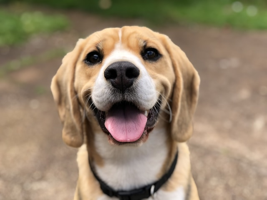


gato:


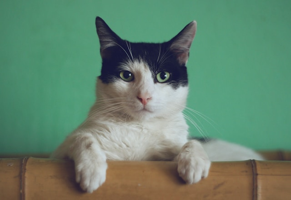


ciudad:


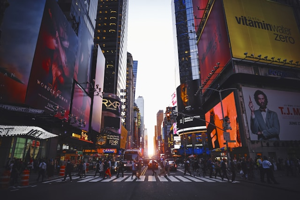


comida:


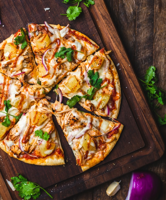

In [4]:
from IPython.display import display
from PIL import Image as PILImage

for name in IMAGES:
    img = PILImage.open(IMG_DIR / f"{name}.jpg")
    img.thumbnail((300, 200))
    print(f"\n{name}:")
    display(img)

## 2. Embeber las imágenes

Cohere `embed-v4.0` espera la imagen como **data URL en base64** (`data:image/jpeg;base64,...`). Pasamos cada imagen al parámetro `images=[...]` del endpoint embed (máx. 1 por llamada).

In [5]:
def image_to_data_url(path: Path) -> str:
    """Convierte un archivo de imagen a data URL base64 (formato que Cohere espera)."""
    suffix = path.suffix.lower().lstrip(".")
    mime = {"jpg": "jpeg", "jpeg": "jpeg", "png": "png", "webp": "webp"}.get(suffix, "jpeg")
    b64 = base64.b64encode(path.read_bytes()).decode("ascii")
    return f"data:image/{mime};base64,{b64}"

image_data_urls = {name: image_to_data_url(IMG_DIR / f"{name}.jpg") for name in IMAGES}

# Una llamada por imagen (la API limita a 1 imagen por request)
image_embeddings = {}
for name, data_url in image_data_urls.items():
    res = co.embed(
        images=[data_url],
        model="embed-v4.0",
        input_type="search_document",
        embedding_types=["float"],
    )
    image_embeddings[name] = np.array(res.embeddings.float[0])
    print(f"  ✓ {name}  · vector dim {image_embeddings[name].shape[0]}")

  ✓ perro  · vector dim 1536
  ✓ gato  · vector dim 1536
  ✓ ciudad  · vector dim 1536
  ✓ comida  · vector dim 1536


## 3. Embeber un query de texto

El **mismo modelo** acepta también texto. La salida será un vector de la misma dimensión, vivirá en el mismo espacio que las imágenes.

In [6]:
def embed_text(text: str) -> np.ndarray:
    res = co.embed(
        texts=[text],
        model="embed-v4.0",
        input_type="search_query",
        embedding_types=["float"],
    )
    return np.array(res.embeddings.float[0])

query = "un animal pequeño y peludo"
q_emb = embed_text(query)
print(f"  ✓ query · vector dim {q_emb.shape[0]}")

  ✓ query · vector dim 1536


## 4. Búsqueda · texto a imagen

Calculamos similitud coseno entre el query de texto y cada imagen. La imagen ganadora debería ser semánticamente la más cercana al query, **sin que el modelo haya visto nunca esos labels**.

In [7]:
def search_text_to_image(query_text: str):
    q = embed_text(query_text)
    ranked = sorted(
        [(name, cos_sim(q, emb)) for name, emb in image_embeddings.items()],
        key=lambda x: -x[1],
    )
    print(f"\nquery: '{query_text}'")
    for name, s in ranked:
        marker = "  ← TOP" if s == ranked[0][1] else ""
        print(f"  {name:8s} : {s:.3f}{marker}")

search_text_to_image("un animal pequeño y peludo")
search_text_to_image("comida típica española")
search_text_to_image("calles llenas de luces y carteles")
search_text_to_image("playa con palmeras al atardecer")  # ninguna imagen lo cumple bien


query: 'un animal pequeño y peludo'
  gato     : 0.158  ← TOP
  perro    : 0.152
  comida   : 0.021
  ciudad   : -0.009

query: 'comida típica española'
  comida   : 0.137  ← TOP
  gato     : 0.080
  perro    : 0.080
  ciudad   : 0.029

query: 'calles llenas de luces y carteles'
  ciudad   : 0.365  ← TOP
  perro    : 0.044
  gato     : 0.026
  comida   : 0.013

query: 'playa con palmeras al atardecer'
  ciudad   : 0.102  ← TOP
  comida   : 0.061
  perro    : 0.061
  gato     : 0.017


## 5. Búsqueda · imagen a imagen

Como las imágenes y los textos viven en el mismo espacio, también podemos usar **una imagen** como query y encontrar la imagen más parecida del catálogo.

In [8]:
def search_image_to_image(query_name: str):
    q = image_embeddings[query_name]
    ranked = sorted(
        [(name, cos_sim(q, emb)) for name, emb in image_embeddings.items() if name != query_name],
        key=lambda x: -x[1],
    )
    print(f"\nquery image: {query_name}")
    for name, s in ranked:
        marker = "  ← más parecida" if s == ranked[0][1] else ""
        print(f"  {name:8s} : {s:.3f}{marker}")

search_image_to_image("perro")
search_image_to_image("comida")


query image: perro
  gato     : 0.266  ← más parecida
  comida   : 0.164
  ciudad   : 0.117

query image: comida
  perro    : 0.164  ← más parecida
  gato     : 0.161
  ciudad   : 0.120


## 6. ¿Para qué sirve esto en producción?

Casos de uso reales en 2026:

- **E-commerce**: "búscame productos parecidos a esta foto" sin tags manuales
- **RAG sobre PDFs con figuras**: indexas las figuras como imágenes y el texto como texto, todo en el mismo vectorstore. Una query sobre "el gráfico de pérdidas" devuelve la figura correcta
- **Moderación de contenido**: detectar imágenes parecidas a un dataset de referencia
- **Recomendación visual**: "otros usuarios miraron también..." basado en similitud visual

## Cierre

- `embed-v4.0` proyecta texto e imagen al **mismo espacio**
- Mismo cálculo (similitud coseno), mismas operaciones
- Esto era impensable hace 3 años · hoy es 5 líneas de código